# Compact benchmark algorithm comparison

This notebook compares **Exhaustive, Greedy, Heuristic, Uniform, and Random** on one-dimensional and two-dimensional spatial-field datasets generated with fixed cell-specific structural thresholds.

- **Exhaustive** optimizes over every feasible allocation and every node-specific pair/location decision.
- **Greedy** allocates sensors sequentially using the average, over all field pairs, of each pair's best local $P_{ijmn}$. It builds one local minimum-$P_{ijmn}$ tree after allocation.
- **Heuristic** uses the allocation and beam-search procedure defined in the implementation.
- **Uniform** uses a near-uniform allocation and a seeded random pair-location tree.
- **Random** provides a seeded random allocation and seeded random pair-location tree.

All methods are evaluated using the final sequential misclassification probability under equal field priors.

In [1]:
# Resolve the project whether Jupyter starts here or from the repository root.
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

working = Path.cwd().resolve()
PROJECT = working / "problem-2-min-error-seq" if (working / "problem-2-min-error-seq").is_dir() else working
SOURCE = PROJECT / "src"
if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

from analysis import run_analysis
from figures import save_figures, summary_markdown

## Experimental settings

`test` mode selects **180 cases per spatial dimension**, balanced as 60 Gaussian, 60 quadratic, and 60 sinusoidal cases. `full` mode uses all eligible compact cases. Exhaustive search is restricted by `EXACT_K_MAX`; the compact datasets currently contain $K\in\{3,4\}$.

The time limit applies independently to each method-budget evaluation. Checkpoint reuse is enabled so an interrupted run can continue without recomputing completed records.

In [2]:
# Use "full" for the complete study after confirming the test run.
RUN_MODE = "test"
RESUME = True
TIME_LIMIT_SECONDS = 30.0
EXACT_K_MAX = 4

# These controls apply only to the heuristic method.
BEAM_WIDTH = 3
MAX_ITERATIONS = 30

# This notebook is intentionally tied to the compact datasets.
STUDY = "compact"

## Run the matched comparison

Each method is run on the same selected case and sensor-budget combinations. A record is written immediately after each method-budget evaluation. The summary retains only matched combinations completed successfully by every requested method.

In [3]:
# Run or resume the compact comparison with the settings above.
analysis = run_analysis(
    project=PROJECT,
    study=STUDY,
    mode=RUN_MODE,
    resume=RESUME,
    exact_k_max=EXACT_K_MAX,
    time_limit=TIME_LIMIT_SECONDS,
    beam_width=BEAM_WIDTH,
    max_iterations=MAX_ITERATIONS,
)

# Confirm that this notebook used both compact datasets and all five methods.
expected_datasets = {"compact_benchmark_1d", "compact_benchmark_2d"}
expected_methods = {"Exhaustive", "Greedy", "Heuristic", "Uniform", "Random"}
observed_datasets = {row["dataset"] for row in analysis["rows"]}
observed_methods = {row["method"] for row in analysis["rows"]}
assert observed_datasets == expected_datasets
assert observed_methods == expected_methods

case_counts = {
    dimension: len({
        (row["dataset"], row["case"])
        for row in analysis["rows"]
        if int(row["dimension"]) == dimension
    })
    for dimension in (1, 2)
}
if RUN_MODE == "test":
    assert min(case_counts.values()) >= 180

print("Verified datasets:", sorted(observed_datasets))
print("Verified methods:", sorted(observed_methods))
print("Unique cases by dimension:", case_counts)
print("Results directory:", analysis["output"])

compact/test: 360 cases, methods: Exhaustive, Greedy, Heuristic, Uniform, Random
Exact comparison uses K <= 4; limit 30s per method/budget.
1/360 cases; 0 cached method results
10/360 cases; 0 cached method results
20/360 cases; 0 cached method results
30/360 cases; 0 cached method results
40/360 cases; 0 cached method results
50/360 cases; 0 cached method results
60/360 cases; 0 cached method results
70/360 cases; 0 cached method results
80/360 cases; 0 cached method results
90/360 cases; 0 cached method results
100/360 cases; 0 cached method results
110/360 cases; 0 cached method results
120/360 cases; 0 cached method results
130/360 cases; 0 cached method results
140/360 cases; 0 cached method results
150/360 cases; 0 cached method results
160/360 cases; 0 cached method results
170/360 cases; 0 cached method results
180/360 cases; 0 cached method results
190/360 cases; 0 cached method results
200/360 cases; 0 cached method results
210/360 cases; 0 cached method results
220/360 cases

## Completion and matched summary

The completion counts expose timeouts or missing results before aggregation. The table reports the matched case count, mean budget fraction, mean error probability, mean runtime, and error above Exhaustive where applicable.

In [4]:
# Report method completion before displaying aggregate values.
from collections import Counter

completion = Counter((row["method"], row["status"]) for row in analysis["rows"])
print("Method-status counts:", completion)
display(Markdown(summary_markdown(analysis["summary"])))

Method-status counts: Counter({('Exhaustive', 'ok'): 1417, ('Greedy', 'ok'): 1417, ('Heuristic', 'ok'): 1417, ('Uniform', 'ok'): 1417, ('Random', 'ok'): 1417})


| Dimension | Budget | Method | Cases | Mean Error Probability | Mean Time (s) | Mean Gap |
|---|---:|---|---:|---:|---:|---:|
| One-dimensional | 1 | Exhaustive | 180 | 0.31242 | 0.0025 | 0.00000 |
| One-dimensional | 1 | Greedy | 180 | 0.31564 | 0.0002 | 0.00322 |
| One-dimensional | 1 | Heuristic | 180 | 0.31419 | 0.0004 | 0.00176 |
| One-dimensional | 1 | Random | 180 | 0.56509 | 0.0001 | 0.25267 |
| One-dimensional | 1 | Uniform | 180 | 0.55790 | 0.0001 | 0.24548 |
| One-dimensional | 2 | Exhaustive | 180 | 0.16754 | 0.0068 | 0.00000 |
| One-dimensional | 2 | Greedy | 180 | 0.19053 | 0.0003 | 0.02299 |
| One-dimensional | 2 | Heuristic | 180 | 0.17978 | 0.0005 | 0.01224 |
| One-dimensional | 2 | Random | 180 | 0.49182 | 0.0001 | 0.32428 |
| One-dimensional | 2 | Uniform | 180 | 0.48000 | 0.0001 | 0.31246 |
| One-dimensional | 3 | Exhaustive | 180 | 0.07723 | 0.0139 | 0.00000 |
| One-dimensional | 3 | Greedy | 180 | 0.11735 | 0.0003 | 0.04012 |
| One-dimensional | 3 | Heuristic | 180 | 0.08888 | 0.0005 | 0.01165 |
| One-dimensional | 3 | Random | 180 | 0.41578 | 0.0001 | 0.33855 |
| One-dimensional | 3 | Uniform | 180 | 0.40222 | 0.0001 | 0.32499 |
| One-dimensional | 4 | Exhaustive | 166 | 0.04301 | 0.0227 | 0.00000 |
| One-dimensional | 4 | Greedy | 166 | 0.08657 | 0.0004 | 0.04356 |
| One-dimensional | 4 | Heuristic | 166 | 0.05190 | 0.0006 | 0.00890 |
| One-dimensional | 4 | Random | 166 | 0.34759 | 0.0001 | 0.30459 |
| One-dimensional | 4 | Uniform | 166 | 0.34882 | 0.0001 | 0.30582 |
| Two-dimensional | 1 | Exhaustive | 180 | 0.33760 | 0.0026 | 0.00000 |
| Two-dimensional | 1 | Greedy | 180 | 0.34091 | 0.0002 | 0.00332 |
| Two-dimensional | 1 | Heuristic | 180 | 0.33917 | 0.0004 | 0.00158 |
| Two-dimensional | 1 | Random | 180 | 0.57567 | 0.0001 | 0.23807 |
| Two-dimensional | 1 | Uniform | 180 | 0.57052 | 0.0001 | 0.23292 |
| Two-dimensional | 2 | Exhaustive | 180 | 0.19857 | 0.0070 | 0.00000 |
| Two-dimensional | 2 | Greedy | 180 | 0.21745 | 0.0003 | 0.01888 |
| Two-dimensional | 2 | Heuristic | 180 | 0.21010 | 0.0005 | 0.01153 |
| Two-dimensional | 2 | Random | 180 | 0.51424 | 0.0001 | 0.31567 |
| Two-dimensional | 2 | Uniform | 180 | 0.50128 | 0.0001 | 0.30270 |
| Two-dimensional | 3 | Exhaustive | 180 | 0.10816 | 0.0138 | 0.00000 |
| Two-dimensional | 3 | Greedy | 180 | 0.14409 | 0.0003 | 0.03593 |
| Two-dimensional | 3 | Heuristic | 180 | 0.11815 | 0.0005 | 0.00999 |
| Two-dimensional | 3 | Random | 180 | 0.44472 | 0.0001 | 0.33656 |
| Two-dimensional | 3 | Uniform | 180 | 0.42581 | 0.0001 | 0.31765 |
| Two-dimensional | 4 | Exhaustive | 171 | 0.06881 | 0.0231 | 0.00000 |
| Two-dimensional | 4 | Greedy | 171 | 0.10722 | 0.0004 | 0.03841 |
| Two-dimensional | 4 | Heuristic | 171 | 0.07542 | 0.0006 | 0.00661 |
| Two-dimensional | 4 | Random | 171 | 0.40441 | 0.0001 | 0.33560 |
| Two-dimensional | 4 | Uniform | 171 | 0.38277 | 0.0001 | 0.31396 |

## Comparison figures

The primary figure plots **mean error probability versus mean budget fraction** for each method, with separate panels for the one-dimensional and two-dimensional datasets. Runtime and error-gap figures are exported as supporting comparisons. All plotted points use the same matched samples as the table.

### Error Probability

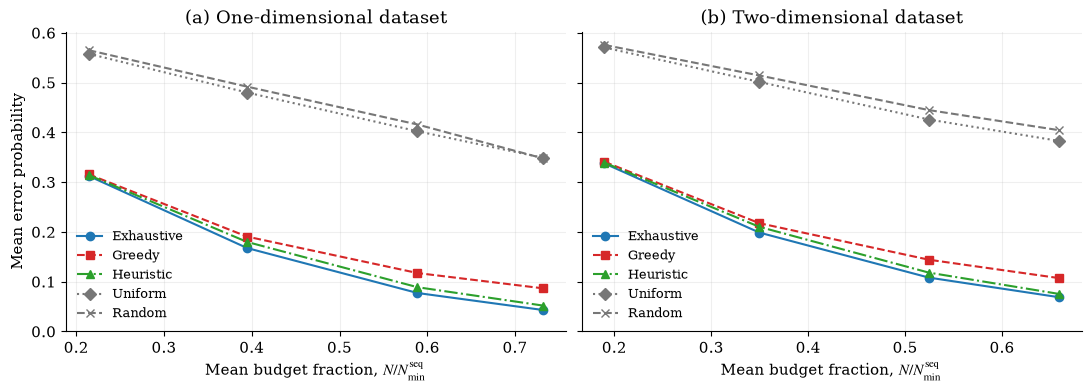

### Seconds

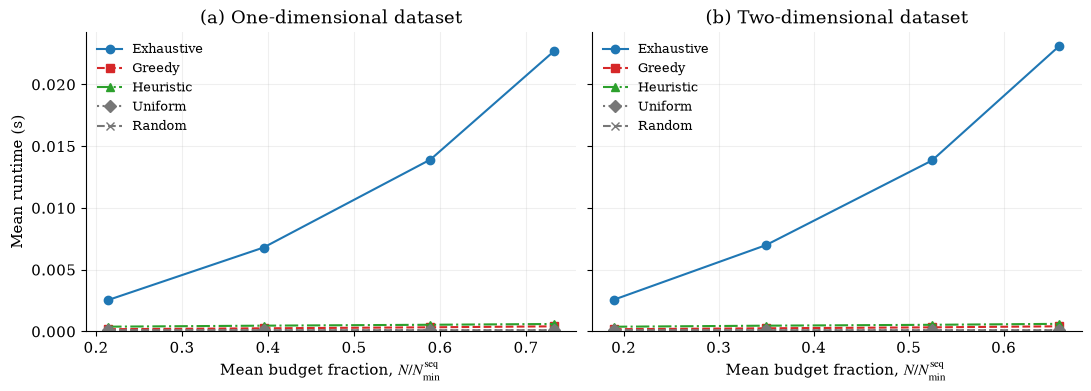

### Error Gap

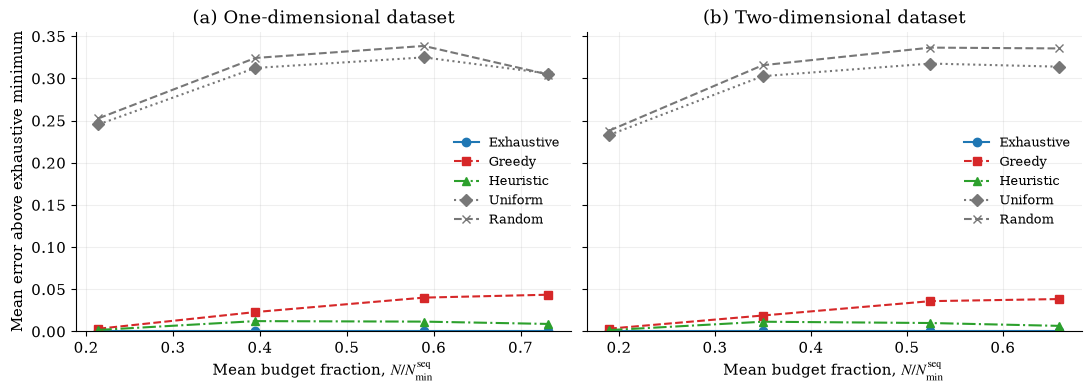

In [5]:
# Save publication-quality PDF and PNG versions, then display each figure.
if not analysis["summary"]:
    raise RuntimeError("No matched completed cases are available for plotting")

figures = save_figures(
    analysis["summary"],
    analysis["output"],
    include_exact=True,
)
for name, figure in figures.items():
    display(Markdown(f"### {name.replace('_', ' ').title()}"))
    display(figure)
    plt.close(figure)